# Lab 9: Building ML models for EEG seizure recognition

**AI in Healthcare · Unit II: Clinical applications of AI**

**Task:** binary classification of **one ~1-second single-channel EEG segment** (178 values) as seizure (`1`) or non-seizure (`0`).
**Unit of analysis:** one segment, not one recording and not one person.

> Educational exercise only. The model is not a diagnostic tool and is **not** ready for clinical use.

**Data source:** [Epileptic Seizure Recognition (Kaggle, harunshimanto)](https://www.kaggle.com/datasets/harunshimanto/epileptic-seizure-recognition), a reshaped CSV of the Bonn EEG dataset (Andrzejak et al., 2001), downloaded with the Kaggle API and read from the relative path `data/Epileptic Seizure Recognition.csv`. The CSV is not part of the submission.

**Reproducibility:** `SEED = 42` for every split and model.

In [1]:
import time, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from scipy.signal import welch

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score, brier_score_loss,
                             roc_curve, precision_recall_curve, f1_score)
from sklearn.calibration import calibration_curve

SEED = 42
FS = 173.61  # Hz, reported sampling rate of the Bonn recordings (Andrzejak et al. 2001)
warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)

df = pd.read_csv(Path("data") / "Epileptic Seizure Recognition.csv")
print("shape:", df.shape)
df.head(3)

shape: (11500, 180)


,Unnamed,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,X21.V1.791,135,190,229,223,192,125,55,-9,-33,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,X15.V1.924,386,382,356,331,320,315,307,272,244,...,164,150,146,152,157,156,154,143,129,1
2,X8.V1.1,-32,-39,-47,-37,-32,-36,-57,-73,-85,...,57,64,48,19,-12,-30,-35,-35,-36,5


## Part A — Load, check, and define the target

In [2]:
sig_cols = [f"X{i}" for i in range(1, 179)]
print("Missing values:", int(df.isna().sum().sum()))
print("Columns:", df.columns[0], "...", df.columns[-1], "| signal columns:", len(sig_cols))
label_names = {1: "seizure", 2: "tumour area", 3: "healthy area (tumour pt)", 4: "healthy, eyes closed", 5: "healthy, eyes open"}
display(df["y"].value_counts().sort_index().rename(index=label_names).to_frame("rows"))

# Recording ID = everything after the first dot of the identifier (e.g. X21.V1.791 -> V1.791)
df["chunk"] = df["Unnamed"].str.split(".", n=1).str[0]
df["recording_id"] = df["Unnamed"].str.split(".", n=1).str[1]
per_rec = df.groupby("recording_id").agg(rows=("y", "size"), n_labels=("y", "nunique"), label=("y", "first"))
print("Recordings:", len(per_rec))
print("Rows per recording:", per_rec.rows.value_counts().to_dict())
print("Labels per recording:", per_rec.n_labels.value_counts().to_dict())
print("Recordings per original label:", per_rec.label.value_counts().sort_index().to_dict())
print("Distinct chunk numbers:", df.chunk.nunique())
assert len(per_rec) == 500 and (per_rec.rows == 23).all() and (per_rec.n_labels == 1).all()

df["seizure"] = (df["y"] == 1).astype(int)
print(f"\nPositive (seizure) rows: {df.seizure.sum()} of {len(df)} = {100 * df.seizure.mean():.1f}%")
print(f"Accuracy of always predicting 'non-seizure': {1 - df.seizure.mean():.3f}")

Missing values: 0
Columns: Unnamed ... y | signal columns: 178


,rows
y,
seizure,2300
tumour area,2300
healthy area (tumour pt),2300
"healthy, eyes closed",2300
"healthy, eyes open",2300


Recordings: 500
Rows per recording: {23: 500}
Labels per recording: {1: 500}
Recordings per original label: {1: 100, 2: 100, 3: 100, 4: 100, 5: 100}
Distinct chunk numbers: 23

Positive (seizure) rows: 2300 of 11500 = 20.0%
Accuracy of always predicting 'non-seizure': 0.800


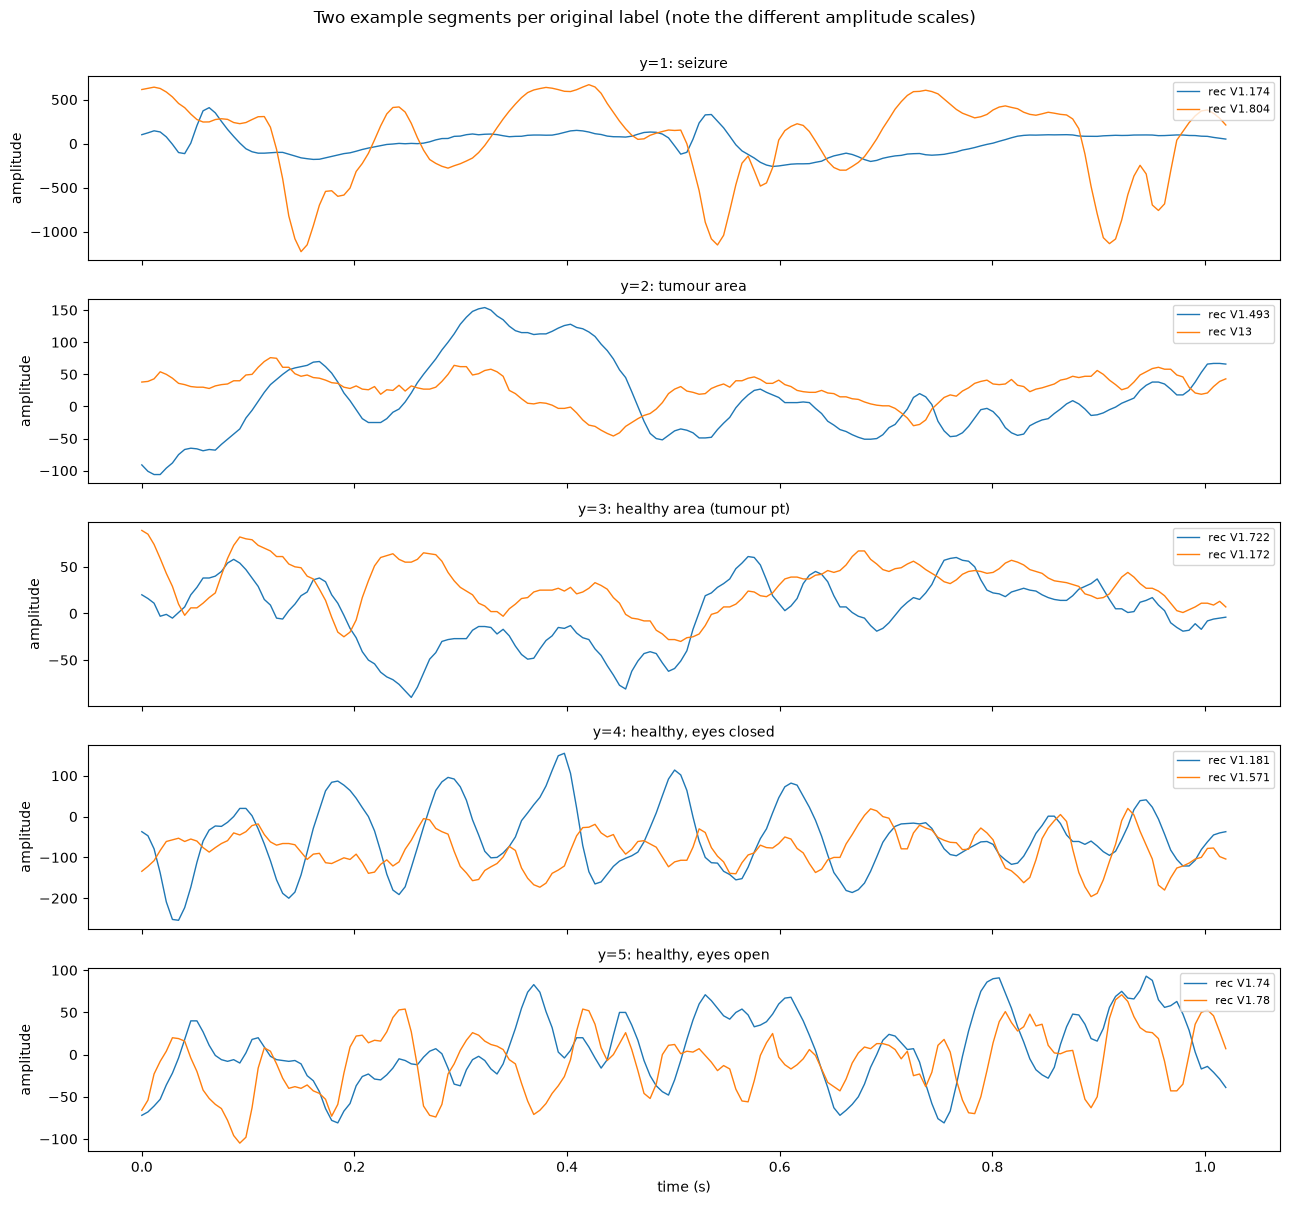

,mean,50%,max
y,,,
seizure,1382.0,1194.0,3696.0
tumour area,283.0,206.0,2474.0
healthy area (tumour pt),214.0,199.0,973.0
"healthy, eyes closed",288.0,269.0,732.0
"healthy, eyes open",189.0,186.0,421.0


In [3]:
t = np.arange(178) / FS
fig, axes = plt.subplots(5, 1, figsize=(13, 12), sharex=True)
rng_p = np.random.default_rng(SEED)
for ax, lab in zip(axes, range(1, 6)):
    recs = rng_p.choice(per_rec.index[per_rec.label == lab], 2, replace=False)
    for r in recs:
        row = df[df.recording_id == r].iloc[0]
        ax.plot(t, row[sig_cols].to_numpy(float), lw=1, label=f"rec {r}")
    ax.set_title(f"y={lab}: {label_names[lab]}", fontsize=10); ax.set_ylabel("amplitude")
    ax.legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("time (s)")
plt.suptitle("Two example segments per original label (note the different amplitude scales)", y=1.0)
plt.tight_layout(); plt.show()

amp = df.assign(ptp=df[sig_cols].max(axis=1) - df[sig_cols].min(axis=1)).groupby("y").ptp.describe()[["mean", "50%", "max"]]
display(amp.rename(index=label_names).round(0))

### Part A — answers

**Checks:** 11,500 rows × 180 columns, **no missing values**, and 2,300 rows for each of the 5 original labels. The identifier gives **500 recordings × 23 chunks**: every recording has exactly 23 rows and a single label, with 100 recordings per label. The binary target has **2,300 positive rows (20.0%)**.

**Row, recording, person.** A *row* is one ~1.02 s chunk (178 samples at 173.61 Hz) of a single-channel EEG. A *recording* is the ~23.6 s single-channel segment the 23 chunks were cut from (shared ID such as `V1.791`). A *person* is the human it came from. The Bonn set has only **5 healthy volunteers (sets A/B, labels 5/4) and 5 epilepsy patients (sets C/D/E, labels 3/2/1)**, so many recordings come from the same person, and the CSV has no person ID at all. 11,500 rows are therefore nowhere near 11,500 independent observations.

**Always predicting "non-seizure"** gives **80.0% accuracy**, with 0% sensitivity: it never finds a seizure. Accuracy rewards the majority class, so it says little about the clinically important error. That is why sensitivity, specificity, PPV/NPV and PR-AUC are reported.

**Why 20% says nothing about real prevalence.** The dataset was *constructed* with 100 recordings per class, and the seizure segments were pre-selected by experts from ictal periods. In real long-term EEG monitoring, seizure activity typically occupies well under 1% of recorded time. The same model would therefore have much lower PPV in practice (see Part D).

**Plots:** seizure segments have far larger amplitude (median peak-to-peak ≈ 1,194 vs ≈ 186–269 for the other labels) and rhythmic, high-amplitude oscillation. The other four classes look similar to each other by eye.

## Part B — Split without leakage (by recording)

In [4]:
groups = df["recording_id"].to_numpy()
y_bin = df["seizure"].to_numpy()

# 1) Hold out ~20% of recordings as the test set
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
dev_idx, test_idx = next(sgkf.split(df, y_bin, groups))
# 2) Split the remaining ~80% into train (60% overall) and validation (20% overall)
sgkf2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=SEED)
tr_rel, va_rel = next(sgkf2.split(df.iloc[dev_idx], y_bin[dev_idx], groups[dev_idx]))
train_idx, val_idx = dev_idx[tr_rel], dev_idx[va_rel]

sets = {"train": train_idx, "validation": val_idx, "test": test_idx}
rec_sets = {k: set(groups[v]) for k, v in sets.items()}
assert not (rec_sets["train"] & rec_sets["validation"]) and not (rec_sets["train"] & rec_sets["test"]) \
    and not (rec_sets["validation"] & rec_sets["test"]), "recording leakage!"
print("No recording ID appears in more than one set.")
display(pd.DataFrame({k: {"rows": len(v), "recordings": len(rec_sets[k]), "seizure_%": 100 * y_bin[v].mean(),
                          **{f"recs y={l}": int((per_rec.loc[list(rec_sets[k]), 'label'] == l).sum()) for l in range(1, 6)}}
                      for k, v in sets.items()}).T.round(1))

X_raw = df[sig_cols].to_numpy(float)
Xtr, Xva, Xte = X_raw[train_idx], X_raw[val_idx], X_raw[test_idx]
ytr, yva, yte = y_bin[train_idx], y_bin[val_idx], y_bin[test_idx]
yorig_va, yorig_te = df["y"].to_numpy()[val_idx], df["y"].to_numpy()[test_idx]
# Scalers are fitted inside each sklearn Pipeline, i.e. on the training rows only.

No recording ID appears in more than one set.


,rows,recordings,seizure_%,recs y=1,recs y=2,recs y=3,recs y=4,recs y=5
train,6900.0,300.0,20.0,60.0,66.0,59.0,53.0,62.0
validation,2300.0,100.0,20.0,20.0,15.0,28.0,20.0,17.0
test,2300.0,100.0,20.0,20.0,19.0,13.0,27.0,21.0


### Part B — answers

The split is done at the **recording level** with `StratifiedGroupKFold`: 300 recordings (6,900 rows) for training, 100 (2,300) for validation and 100 (2,300) for test, each **exactly 20% seizure**. The assertion confirms that no recording ID appears in two sets. The non-seizure labels are not perfectly balanced across sets (e.g. validation has 28 recordings of label 3 but test has 13), because only the binary target was stratified. Scalers are inside each `Pipeline`, so they are fitted on training rows only.

**How a random row split leaks.** The 23 chunks of one recording are consecutive pieces of the same signal, from the same electrode, person, session and amplifier, so they share amplitude level, noise and rhythm. With a random row split, most test chunks have "siblings" from the same recording in the training set. The model can then partly recognise the *recording* instead of learning what seizure activity looks like in general. Test performance becomes an estimate for "new chunks of recordings already seen", which is optimistic compared with the real use case of new recordings (and, ideally, new people). Even our recording-level split cannot prevent the same *person* appearing in both training and test.

The validation set is used for all model comparisons and the threshold choice. The test set is used once, in Part E.

## Part C — Baseline and comparison models

### Raw 178 values

In [5]:
MODELS, VAL_PROBA, TIMES = {}, {}, {}

def fit_model(name, model, Xf, yf, Xv):
    t0 = time.time(); model.fit(Xf, yf); TIMES[name] = time.time() - t0
    MODELS[name] = model
    VAL_PROBA[name] = model.predict_proba(Xv)[:, 1]
    print(f"{name:28s} trained in {TIMES[name]:6.1f}s  | val ROC-AUC = {roc_auc_score(yva, VAL_PROBA[name]):.3f}")

fit_model("LogReg raw (baseline)", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEED)), Xtr, ytr, Xva)
fit_model("Random forest raw", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), Xtr, ytr, Xva)
fit_model("SVM (RBF) raw", make_pipeline(StandardScaler(), SVC(C=1.0, gamma="scale", probability=True, random_state=SEED)), Xtr, ytr, Xva)
fit_model("kNN (k=15) raw", make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15)), Xtr, ytr, Xva)

LogReg raw (baseline)        trained in    0.1s  | val ROC-AUC = 0.505


Random forest raw            trained in    3.2s  | val ROC-AUC = 0.989


SVM (RBF) raw                trained in    1.3s  | val ROC-AUC = 0.990
kNN (k=15) raw               trained in    0.0s  | val ROC-AUC = 0.898


### Engineered features

Time-domain features from the lab, plus (optional extension) relative band power from Welch's method at the reported 173.61 Hz sampling rate.

seizure,0,1
mean,-5.458,-5.410
std,44.514,269.040
min,-113.000,-568.500
max,99.000,558.500
peak_to_peak,211.000,1156.500
energy,2831.986,73499.539
zero_crossings,17.000,13.000
line_length,1924.500,10510.500
mean_abs_slope,10.873,59.381
skew,-0.019,-0.077


LogReg features              trained in    0.0s  | val ROC-AUC = 0.990


Random forest features       trained in    0.5s  | val ROC-AUC = 0.990


Gradient boosting features   trained in    0.8s  | val ROC-AUC = 0.994


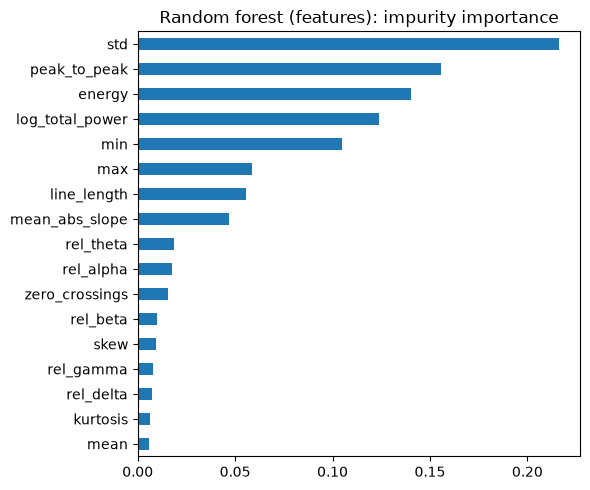

In [6]:
def eeg_features(X):
    d = np.diff(X, axis=1)
    centred = X - X.mean(1, keepdims=True)
    f = pd.DataFrame({
        "mean": X.mean(1), "std": X.std(1), "min": X.min(1), "max": X.max(1),
        "peak_to_peak": X.max(1) - X.min(1),
        "energy": (X ** 2).mean(1),
        "zero_crossings": (np.diff(np.sign(centred), axis=1) != 0).sum(1),
        "line_length": np.abs(d).sum(1),
        "mean_abs_slope": np.abs(d).mean(1),
        "skew": pd.DataFrame(X).skew(axis=1).to_numpy(),
        "kurtosis": pd.DataFrame(X).kurt(axis=1).to_numpy(),
    })
    freqs, psd = welch(X, fs=FS, nperseg=128, axis=1)
    total = psd[:, (freqs >= 0.5) & (freqs < 40)].sum(1)
    for band, (lo, hi) in {"delta": (0.5, 4), "theta": (4, 8), "alpha": (8, 13), "beta": (13, 30), "gamma": (30, 40)}.items():
        f[f"rel_{band}"] = psd[:, (freqs >= lo) & (freqs < hi)].sum(1) / total
    f["log_total_power"] = np.log(total)
    return f

Ftr, Fva, Fte = eeg_features(Xtr), eeg_features(Xva), eeg_features(Xte)
display(pd.concat([Ftr, pd.Series(ytr, name="seizure")], axis=1).groupby("seizure").median().T.round(3))

fit_model("LogReg features", make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000, random_state=SEED)), Ftr, ytr, Fva)
fit_model("Random forest features", RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED), Ftr, ytr, Fva)
fit_model("Gradient boosting features", HistGradientBoostingClassifier(random_state=SEED), Ftr, ytr, Fva)

imp = pd.Series(MODELS["Random forest features"].feature_importances_, index=Ftr.columns).sort_values()
imp.plot.barh(figsize=(6, 5), title="Random forest (features): impurity importance"); plt.tight_layout(); plt.show()

### Optional extension — small 1D CNN on the raw signal

PyTorch could not be installed (the disk was almost full), so this uses the same small NumPy 1D CNN I wrote for Lab 6 (three conv/pool blocks, dense layer, softmax), with gradients verified numerically. Inputs are standardised using the **training-set** mean and SD, and early stopping uses validation F1.

In [7]:
import time
import numpy as np
from numpy.lib.stride_tricks import sliding_window_view


class Conv1D:
    """'Same'-padded 1D convolution, channels-last tensors of shape (N, L, C)."""
    def __init__(self, c_in, c_out, k, rng):
        self.k, self.c_in, self.c_out = k, c_in, c_out
        self.W = (rng.standard_normal((c_in * k, c_out)) * np.sqrt(2.0 / (c_in * k))).astype(np.float32)
        self.b = np.zeros(c_out, np.float32)

    def forward(self, x):
        n, L, _ = x.shape
        p = self.k // 2
        xp = np.pad(x, ((0, 0), (p, self.k - 1 - p), (0, 0)))
        cols = sliding_window_view(xp, self.k, axis=1)          # (N, L, C_in, k)
        self.cols = cols.reshape(n, L, self.c_in * self.k)       # copy -> im2col
        self.x_shape = x.shape
        return self.cols @ self.W + self.b

    def backward(self, dout):
        n, L, _ = self.x_shape
        self.dW = self.cols.reshape(-1, self.c_in * self.k).T @ dout.reshape(-1, self.c_out)
        self.db = dout.sum(axis=(0, 1))
        dcols = (dout @ self.W.T).reshape(n, L, self.c_in, self.k)
        p = self.k // 2
        dxp = np.zeros((n, L + self.k - 1, self.c_in), np.float32)
        for j in range(self.k):                                   # col2im: scatter-add
            dxp[:, j:j + L, :] += dcols[:, :, :, j]
        return dxp[:, p:p + L, :]

    def params(self):
        return [(self.W, "dW"), (self.b, "db")]


class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask

    def backward(self, d):
        return d * self.mask

    def params(self):
        return []


class MaxPool1D:
    """Non-overlapping max pooling of size 2 along the length axis."""
    def forward(self, x):
        n, L, c = x.shape
        self.L = L
        Lh = L // 2
        xr = x[:, :2 * Lh].reshape(n, Lh, 2, c)
        self.arg = xr.argmax(axis=2)
        return xr.max(axis=2)

    def backward(self, d):
        n, Lh, c = d.shape
        dx = np.zeros((n, self.L, c), np.float32)
        dr = dx[:, :2 * Lh].reshape(n, Lh, 2, c)
        np.put_along_axis(dr, self.arg[:, :, None, :], d[:, :, None, :], axis=2)
        return dx

    def params(self):
        return []


class Flatten:
    def forward(self, x):
        self.shape = x.shape
        return x.reshape(x.shape[0], -1)

    def backward(self, d):
        return d.reshape(self.shape)

    def params(self):
        return []


class Dense:
    def __init__(self, d_in, d_out, rng):
        self.W = (rng.standard_normal((d_in, d_out)) * np.sqrt(2.0 / d_in)).astype(np.float32)
        self.b = np.zeros(d_out, np.float32)

    def forward(self, x):
        self.x = x
        return x @ self.W + self.b

    def backward(self, d):
        self.dW = self.x.T @ d
        self.db = d.sum(axis=0)
        return d @ self.W.T

    def params(self):
        return [(self.W, "dW"), (self.b, "db")]


class Dropout:
    def __init__(self, p, rng):
        self.p, self.rng, self.training = p, rng, True

    def forward(self, x):
        if not self.training or self.p == 0:
            return x
        self.mask = (self.rng.random(x.shape) >= self.p).astype(np.float32) / (1 - self.p)
        return x * self.mask

    def backward(self, d):
        return d * self.mask if self.training and self.p > 0 else d

    def params(self):
        return []


class NumpyCNN1D:
    """Small 1D CNN: [Conv-ReLU-Pool] x 3 -> Dense(64) -> Dropout -> Dense(n_classes).
    Trained with mini-batch Adam on softmax cross-entropy; early stopping on validation macro F1."""

    def __init__(self, length=187, n_classes=5, channels=(16, 32, 32), kernels=(7, 5, 3), hidden=64,
                 dropout=0.3, seed=42):
        rng = np.random.default_rng(seed)
        self.rng = rng
        layers, c_in, L = [], 1, length
        for c_out, k in zip(channels, kernels):
            layers += [Conv1D(c_in, c_out, k, rng), ReLU(), MaxPool1D()]
            c_in, L = c_out, L // 2
        layers += [Flatten(), Dense(c_in * L, hidden, rng), ReLU(), Dropout(dropout, rng),
                   Dense(hidden, n_classes, rng)]
        self.layers = layers
        self.n_classes = n_classes

    def _set_training(self, flag):
        for l in self.layers:
            if isinstance(l, Dropout):
                l.training = flag

    def _forward(self, x):
        for l in self.layers:
            x = l.forward(x)
        return x

    def _backward(self, d):
        for l in reversed(self.layers):
            d = l.backward(d)

    def predict_proba(self, X, batch=2048):
        self._set_training(False)
        out = []
        for i in range(0, len(X), batch):
            z = self._forward(X[i:i + batch, :, None].astype(np.float32))
            z = z - z.max(axis=1, keepdims=True)
            e = np.exp(z)
            out.append(e / e.sum(axis=1, keepdims=True))
        return np.vstack(out)

    def predict(self, X):
        return self.predict_proba(X).argmax(axis=1)

    def fit(self, X, y, X_val, y_val, epochs=30, batch=128, lr=1e-3, patience=4, score_fn=None,
            class_weight=None, verbose=True):
        params = [(p, l, g) for l in self.layers for p, g in l.params()]
        m = [np.zeros_like(p) for p, _, _ in params]
        v = [np.zeros_like(p) for p, _, _ in params]
        b1, b2, eps, t = 0.9, 0.999, 1e-8, 0
        cw = np.ones(self.n_classes, np.float32) if class_weight is None else np.asarray(class_weight, np.float32)
        best, best_state, wait = -np.inf, None, 0
        self.history = []
        n = len(X)
        for epoch in range(1, epochs + 1):
            t0 = time.time()
            self._set_training(True)
            order = self.rng.permutation(n)
            total_loss = 0.0
            for i in range(0, n, batch):
                idx = order[i:i + batch]
                xb, yb = X[idx, :, None].astype(np.float32), y[idx]
                z = self._forward(xb)
                z = z - z.max(axis=1, keepdims=True)
                p = np.exp(z); p /= p.sum(axis=1, keepdims=True)
                w = cw[yb]
                total_loss += float(-(w * np.log(p[np.arange(len(yb)), yb] + 1e-12)).sum())
                d = p.copy(); d[np.arange(len(yb)), yb] -= 1
                d *= (w / w.sum())[:, None]
                self._backward(d.astype(np.float32))
                t += 1
                for j, (prm, layer, gname) in enumerate(params):
                    g = getattr(layer, gname)
                    m[j] = b1 * m[j] + (1 - b1) * g
                    v[j] = b2 * v[j] + (1 - b2) * g * g
                    prm -= (lr * (m[j] / (1 - b1 ** t)) / (np.sqrt(v[j] / (1 - b2 ** t)) + eps)).astype(np.float32)
            val_pred = self.predict(X_val)
            score = score_fn(y_val, val_pred)
            self.history.append({"epoch": epoch, "train_loss": total_loss / n, "val_macro_f1": score,
                                 "seconds": time.time() - t0})
            if verbose:
                print(f"epoch {epoch:2d}  train_loss={total_loss / n:.4f}  val_macro_F1={score:.4f}  ({time.time() - t0:.0f}s)")
            if score > best:
                best, wait = score, 0
                best_state = [prm.copy() for prm, _, _ in params]
                self.best_epoch = epoch
            else:
                wait += 1
                if wait >= patience:
                    if verbose:
                        print(f"early stopping: no improvement for {patience} epochs; restoring epoch {self.best_epoch}")
                    break
        for (prm, _, _), saved in zip(params, best_state):
            prm[...] = saved
        return self

In [8]:
mu, sd = Xtr.mean(), Xtr.std()
cnn = NumpyCNN1D(length=178, n_classes=2, seed=SEED)
t0 = time.time()
cnn.fit(((Xtr - mu) / sd).astype(np.float32), ytr, ((Xva - mu) / sd).astype(np.float32), yva,
        epochs=40, batch=64, lr=1e-3, patience=6, score_fn=lambda a, b: f1_score(a, b), verbose=False)
TIMES["1D CNN (NumPy, ext.)"] = time.time() - t0

class _CNNWrap:
    def predict_proba(self, X):
        return cnn.predict_proba(((X - mu) / sd).astype(np.float32))
MODELS["1D CNN (NumPy, ext.)"] = _CNNWrap()
VAL_PROBA["1D CNN (NumPy, ext.)"] = MODELS["1D CNN (NumPy, ext.)"].predict_proba(Xva)[:, 1]
print(f"1D CNN trained in {TIMES['1D CNN (NumPy, ext.)']:.0f}s, best epoch {cnn.best_epoch}, "
      f"val ROC-AUC = {roc_auc_score(yva, VAL_PROBA['1D CNN (NumPy, ext.)']):.3f}")

1D CNN trained in 14s, best epoch 12, val ROC-AUC = 0.993


### Part C — answers

**Raw values vs engineered features: features worked better.** On validation, gradient boosting on features reached ROC-AUC 0.994 and PR-AUC 0.985. Random forest on features beat random forest on raw values: PR-AUC 0.980 vs 0.971, and sensitivity at 0.5 of 0.91 vs 0.87. Logistic regression shows the starkest difference: **on raw values it is no better than chance (ROC-AUC 0.505), but on features it reaches 0.990.**

The reason is that each raw column `X_k` is the voltage at a fixed time offset within an arbitrarily cut chunk. Seizure oscillations can be at any phase, so at any single time point the seizure and non-seizure values have almost the same mean (both ≈ −5). What differs is **variability, amplitude and rhythm**: std 269 vs 45, line length 10,500 vs 1,900, and relative theta power 0.45 vs 0.22. A linear model on raw values cannot compute these, while features compute them directly. Tree ensembles and the RBF-SVM can approximate them from raw values, but less efficiently. The 1D CNN (optional extension) learns such phase-invariant filters itself and performs almost as well as the best feature model (ROC-AUC 0.993).

**Easiest features to explain to a clinician:** *peak-to-peak amplitude* (how large the voltage swings are), *line length* (how much the trace "travels": larger and faster oscillations give a longer line, a classic seizure-detection feature), *dominant frequency band / relative theta power* (rhythmic activity in a specific band) and *zero-crossing count* (how often the signal crosses its mean). These map onto what neurologists look for visually: high-amplitude, rhythmic, evolving discharges. Skewness, kurtosis and Welch band ratios are harder to communicate.

## Part D — Evaluate on the validation set

,threshold,TP,FP,TN,FN,sensitivity,specificity,PPV,NPV,accuracy,ROC_AUC,PR_AUC,Brier,train_seconds,input
Gradient boosting features,0.5,422.0,7.0,1833.0,38.0,0.917,0.996,0.984,0.980,0.980,0.994,0.985,0.016,0.751,features
"1D CNN (NumPy, ext.)",0.5,435.0,17.0,1823.0,25.0,0.946,0.991,0.962,0.986,0.982,0.993,0.984,0.017,13.899,raw signal
Random forest features,0.5,420.0,11.0,1829.0,40.0,0.913,0.994,0.974,0.979,0.978,0.990,0.980,0.018,0.481,features
LogReg features,0.5,415.0,16.0,1824.0,45.0,0.902,0.991,0.963,0.976,0.973,0.990,0.975,0.022,0.029,features
Random forest raw,0.5,401.0,25.0,1815.0,59.0,0.872,0.986,0.941,0.969,0.963,0.989,0.971,0.030,3.216,raw signal
SVM (RBF) raw,0.5,390.0,24.0,1816.0,70.0,0.848,0.987,0.942,0.963,0.959,0.990,0.969,0.031,1.262,raw signal
kNN (k=15) raw,0.5,220.0,4.0,1836.0,240.0,0.478,0.998,0.982,0.884,0.894,0.898,0.826,0.084,0.004,raw signal
LogReg raw (baseline),0.5,67.0,4.0,1836.0,393.0,0.146,0.998,0.944,0.824,0.827,0.505,0.452,0.150,0.056,raw signal


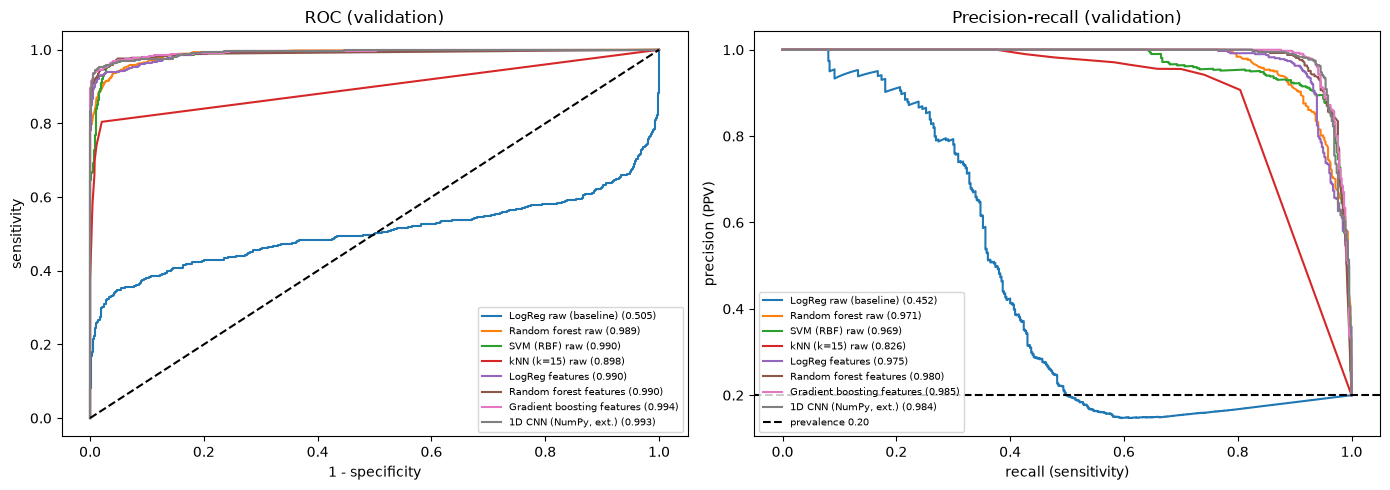

Best validation model by PR-AUC: Gradient boosting features


In [9]:
def binary_metrics(y, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {"threshold": thr, "TP": tp, "FP": fp, "TN": tn, "FN": fn,
            "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp),
            "PPV": tp / (tp + fp) if tp + fp else np.nan, "NPV": tn / (tn + fn) if tn + fn else np.nan,
            "accuracy": (tp + tn) / len(y),
            "ROC_AUC": roc_auc_score(y, proba), "PR_AUC": average_precision_score(y, proba),
            "Brier": brier_score_loss(y, proba)}

FEATURE_MODELS = {"LogReg features", "Random forest features", "Gradient boosting features"}
val_table = pd.DataFrame({n: binary_metrics(yva, p) for n, p in VAL_PROBA.items()}).T
val_table["train_seconds"] = pd.Series(TIMES)
val_table["input"] = ["features" if n in FEATURE_MODELS else "raw signal" for n in val_table.index]
val_table = val_table.sort_values("PR_AUC", ascending=False)
display(val_table.astype({c: float for c in val_table.columns if c != "input"}).round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for n, p in VAL_PROBA.items():
    fpr, tpr, _ = roc_curve(yva, p); axes[0].plot(fpr, tpr, label=f"{n} ({roc_auc_score(yva, p):.3f})")
    pr, rc, _ = precision_recall_curve(yva, p); axes[1].plot(rc, pr, label=f"{n} ({average_precision_score(yva, p):.3f})")
axes[0].plot([0, 1], [0, 1], "k--"); axes[0].set(xlabel="1 - specificity", ylabel="sensitivity", title="ROC (validation)")
axes[1].axhline(yva.mean(), color="k", ls="--", label=f"prevalence {yva.mean():.2f}")
axes[1].set(xlabel="recall (sensitivity)", ylabel="precision (PPV)", title="Precision-recall (validation)")
for ax in axes: ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

best_name = val_table.index[0]
print("Best validation model by PR-AUC:", best_name)

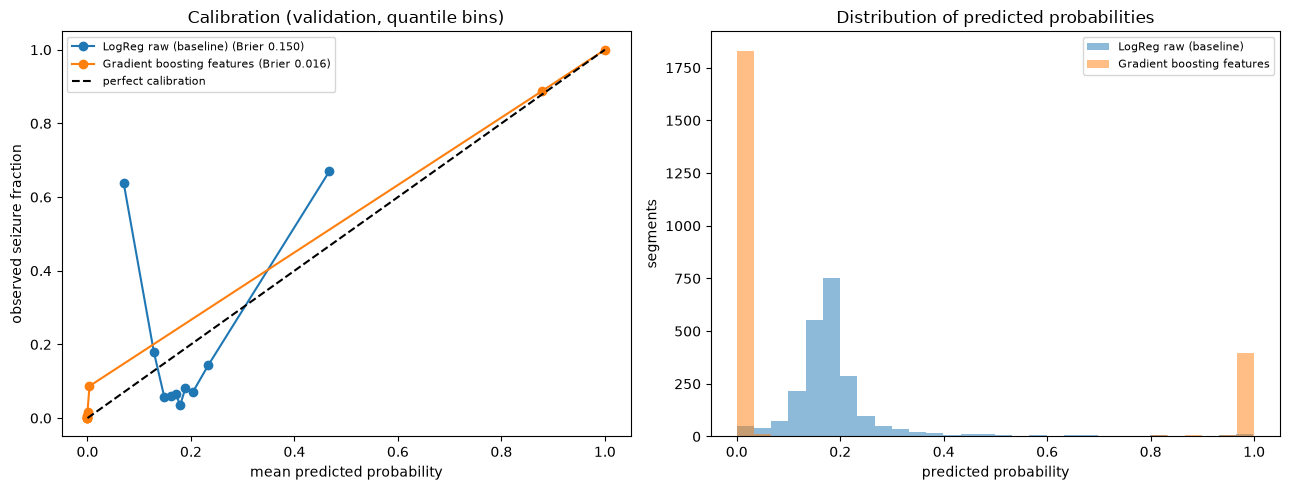

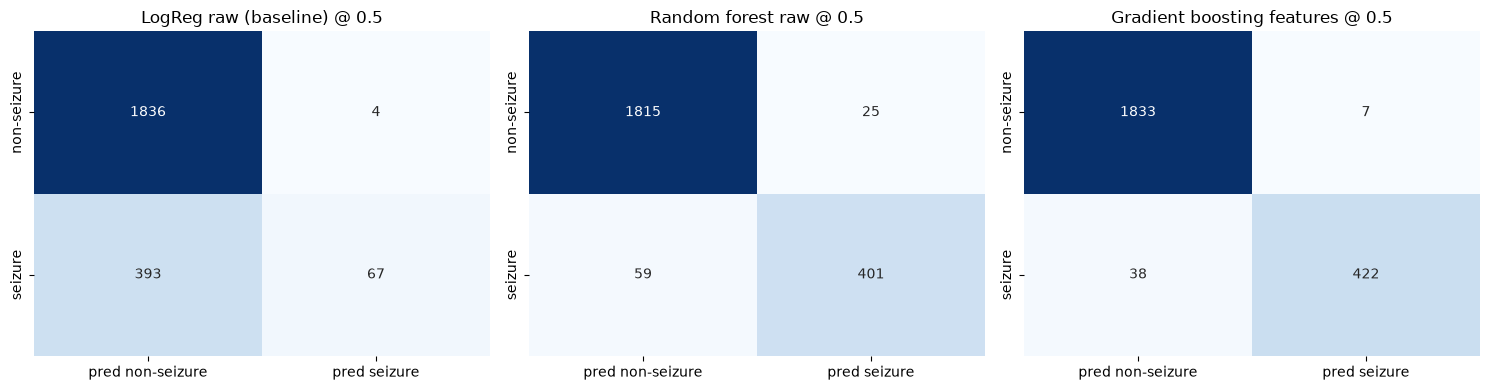

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for n in ["LogReg raw (baseline)", best_name]:
    frac_pos, mean_pred = calibration_curve(yva, VAL_PROBA[n], n_bins=10, strategy="quantile")
    axes[0].plot(mean_pred, frac_pos, "o-", label=f"{n} (Brier {brier_score_loss(yva, VAL_PROBA[n]):.3f})")
    axes[1].hist(VAL_PROBA[n], bins=30, alpha=0.5, label=n)
axes[0].plot([0, 1], [0, 1], "k--", label="perfect calibration")
axes[0].set(xlabel="mean predicted probability", ylabel="observed seizure fraction", title="Calibration (validation, quantile bins)")
axes[1].set(xlabel="predicted probability", ylabel="segments", title="Distribution of predicted probabilities")
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, n in zip(axes, ["LogReg raw (baseline)", "Random forest raw", best_name]):
    cm = confusion_matrix(yva, (VAL_PROBA[n] >= 0.5).astype(int))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["pred non-seizure", "pred seizure"], yticklabels=["non-seizure", "seizure"])
    ax.set_title(f"{n} @ 0.5")
plt.tight_layout(); plt.show()

### Choosing the decision threshold

**Rule:** for the selected model, use the **highest threshold that still gives ≥ 95% sensitivity on the validation set**. A missed seizure segment is the costlier error when the tool is a review-prioritisation aid. Taking the highest such threshold keeps false alarms as low as possible subject to that constraint.

In [11]:
p_best = VAL_PROBA[best_name]
cands = np.unique(np.round(p_best, 6))[::-1]
chosen_thr = next(t for t in cands if ((p_best >= t) & (yva == 1)).sum() / (yva == 1).sum() >= 0.95)
thr_tbl = pd.DataFrame([binary_metrics(yva, p_best, thr) for thr in [0.5, chosen_thr]], index=["default 0.5", "chosen (>=95% sens)"])
display(thr_tbl.round(3))
print(f"Chosen threshold = {chosen_thr:.4f}")
print(f"Of every 100 flagged segments, about {100 * thr_tbl.loc['chosen (>=95% sens)', 'PPV']:.0f} are true seizure segments (PPV) "
      f"- at this dataset's 20% prevalence.")

# Does higher ROC-AUC always mean better performance at a fixed operating rule?
rows = []
for n, p in VAL_PROBA.items():
    c = np.unique(np.round(p, 6))[::-1]
    thr_n = next(t for t in c if ((p >= t) & (yva == 1)).sum() / (yva == 1).sum() >= 0.95)
    m = binary_metrics(yva, p, thr_n)
    rows.append({"model": n, "ROC_AUC": m["ROC_AUC"], "thr@95%sens": thr_n, "sensitivity": m["sensitivity"],
                 "specificity": m["specificity"], "FP": m["FP"], "PPV": m["PPV"]})
display(pd.DataFrame(rows).sort_values("ROC_AUC", ascending=False).round(3))

# PPV at realistic prevalences (sensitivity/specificity held fixed)
se, sp = thr_tbl.loc["chosen (>=95% sens)", ["sensitivity", "specificity"]]
prev_tbl = pd.DataFrame({"prevalence": [0.20, 0.05, 0.01, 0.001]})
prev_tbl["PPV"] = se * prev_tbl.prevalence / (se * prev_tbl.prevalence + (1 - sp) * (1 - prev_tbl.prevalence))
display(prev_tbl.round(3))

,threshold,TP,FP,TN,FN,sensitivity,specificity,PPV,NPV,accuracy,ROC_AUC,PR_AUC,Brier
default 0.5,0.500,422,7,1833,38,0.917,0.996,0.984,0.980,0.980,0.994,0.985,0.016
chosen (>=95% sens),0.013,437,42,1798,23,0.950,0.977,0.912,0.987,0.972,0.994,0.985,0.016


Chosen threshold = 0.0126
Of every 100 flagged segments, about 91 are true seizure segments (PPV) - at this dataset's 20% prevalence.


,model,ROC_AUC,thr@95%sens,sensitivity,specificity,FP,PPV
6,Gradient boosting features,0.994,0.013,0.95,0.977,42,0.912
7,"1D CNN (NumPy, ext.)",0.993,0.207,0.95,0.985,27,0.942
5,Random forest features,0.990,0.190,0.95,0.974,47,0.903
4,LogReg features,0.990,0.061,0.95,0.931,127,0.775
2,SVM (RBF) raw,0.990,0.103,0.95,0.972,51,0.895
1,Random forest raw,0.989,0.210,0.95,0.941,108,0.802
3,kNN (k=15) raw,0.898,0.000,1.00,0.000,1840,0.200
0,LogReg raw (baseline),0.505,0.016,0.95,0.001,1839,0.192


,prevalence,PPV
0,0.200,0.912
1,0.050,0.687
2,0.010,0.296
3,0.001,0.040


### Part D — answers

**Selected model:** gradient boosting on engineered features, which had the highest validation PR-AUC (0.985) and ROC-AUC (0.994) and the lowest Brier score (0.016). In the calibration plot its curve is close to the diagonal in the middle range, but most of its predictions sit at the extremes (near 0 or 1). The baseline logistic regression on raw values is essentially uninformative (Brier 0.150, close to always predicting the 0.2 base rate).

**Threshold rule:** *the highest threshold that gives ≥ 95% validation sensitivity.* For the selected model this is a low threshold (≈ 0.013), because the model is very confident on most segments. At that threshold: sensitivity **0.950**, specificity 0.977, **42 false positives** (versus 7 at 0.5) and 23 missed seizure segments (versus 38 at 0.5).

**Missed seizure vs false alarm.** In a *review-prioritisation* workflow, a missed seizure segment is the costlier error. It may never be looked at, and the patient's seizure burden could be under-estimated, affecting diagnosis or medication. A false alarm costs a few seconds of clinician review. I therefore fixed sensitivity at ≥ 95% and accepted more false alarms. The constraint is not 100% because false alarms grow quickly near that limit, and too many alerts cause alert fatigue, which is also a safety risk.

**If the tool flagged 100 segments:** about **91** would be true seizure segments at this threshold. The metric is **PPV (precision)**. That holds only at this dataset's artificial 20% prevalence. Keeping sensitivity and specificity fixed, PPV would be ≈ 69% at 5% prevalence, ≈ 30% at 1%, and ≈ 4% at 0.1%, closer to real long-term monitoring. Most flags would then be false.

**Does higher ROC-AUC always mean better results at my threshold? No.** ROC-AUC summarises ranking over *all* thresholds. At the fixed operating point of 95% sensitivity, the 1D CNN (ROC-AUC 0.993) has fewer false positives (27) than gradient boosting (0.994; 42 FP). The SVM and the feature logistic regression have similar ROC-AUC (0.990) but very different FP counts (51 vs 127). Model choice should consider performance at the intended operating point, not only the overall AUC. Selecting by PR-AUC was a reasonable, pre-stated rule, but the CNN would be a strong alternative for this specific threshold.

## Part E — Final test and error analysis (selected model + threshold, used once)

In [12]:
p_test = MODELS[best_name].predict_proba(Fte if best_name in FEATURE_MODELS else Xte)[:, 1]
test_m = binary_metrics(yte, p_test, chosen_thr)

# Bootstrap 95% CI resampling RECORDINGS (not rows)
rec_te = groups[test_idx]
uniq = np.unique(rec_te)
rows_by_rec = {r: np.flatnonzero(rec_te == r) for r in uniq}
pred_te = (p_test >= chosen_thr).astype(int)
rng_b = np.random.default_rng(SEED)
boot = []
for _ in range(2000):
    idx = np.concatenate([rows_by_rec[r] for r in rng_b.choice(uniq, len(uniq), replace=True)])
    yt, pt = yte[idx], pred_te[idx]
    boot.append(((pt[yt == 1] == 1).mean() if (yt == 1).any() else np.nan, (pt[yt == 0] == 0).mean()))
boot = np.array(boot)
ci = np.nanpercentile(boot, [2.5, 97.5], axis=0)
print(f"Test sensitivity {test_m['sensitivity']:.3f} (95% CI {ci[0, 0]:.3f}-{ci[1, 0]:.3f}); "
      f"specificity {test_m['specificity']:.3f} (95% CI {ci[0, 1]:.3f}-{ci[1, 1]:.3f}) [recording bootstrap, 2000 reps]")

final = val_table.drop(columns=["input"]).copy()
final["split"] = "validation @0.5"
final.loc[f"{best_name} - validation @chosen"] = {**binary_metrics(yva, p_best, chosen_thr), "train_seconds": TIMES[best_name], "split": "validation @chosen"}
final.loc[f"{best_name} - TEST @chosen"] = {**test_m, "train_seconds": TIMES[best_name], "split": "TEST (once)"}
display(final.astype({c: float for c in final.columns if c != "split"}).round(3))

Test sensitivity 0.983 (95% CI 0.952-1.000); specificity 0.962 (95% CI 0.926-0.991) [recording bootstrap, 2000 reps]


,threshold,TP,FP,TN,FN,sensitivity,specificity,PPV,NPV,accuracy,ROC_AUC,PR_AUC,Brier,train_seconds,split
Gradient boosting features,0.500,422.0,7.0,1833.0,38.0,0.917,0.996,0.984,0.980,0.980,0.994,0.985,0.016,0.751,validation @0.5
"1D CNN (NumPy, ext.)",0.500,435.0,17.0,1823.0,25.0,0.946,0.991,0.962,0.986,0.982,0.993,0.984,0.017,13.899,validation @0.5
Random forest features,0.500,420.0,11.0,1829.0,40.0,0.913,0.994,0.974,0.979,0.978,0.990,0.980,0.018,0.481,validation @0.5
LogReg features,0.500,415.0,16.0,1824.0,45.0,0.902,0.991,0.963,0.976,0.973,0.990,0.975,0.022,0.029,validation @0.5
Random forest raw,0.500,401.0,25.0,1815.0,59.0,0.872,0.986,0.941,0.969,0.963,0.989,0.971,0.030,3.216,validation @0.5
SVM (RBF) raw,0.500,390.0,24.0,1816.0,70.0,0.848,0.987,0.942,0.963,0.959,0.990,0.969,0.031,1.262,validation @0.5
kNN (k=15) raw,0.500,220.0,4.0,1836.0,240.0,0.478,0.998,0.982,0.884,0.894,0.898,0.826,0.084,0.004,validation @0.5
LogReg raw (baseline),0.500,67.0,4.0,1836.0,393.0,0.146,0.998,0.944,0.824,0.827,0.505,0.452,0.150,0.056,validation @0.5
Gradient boosting features - validation @chosen,0.013,437.0,42.0,1798.0,23.0,0.950,0.977,0.912,0.987,0.972,0.994,0.985,0.016,0.751,validation @chosen
Gradient boosting features - TEST @chosen,0.013,452.0,70.0,1770.0,8.0,0.983,0.962,0.866,0.996,0.966,0.996,0.984,0.025,0.751,TEST (once)


,rows,FP,FN,FP_rate
1: seizure,460,0,8,0.000
2: tumour area,437,24,0,0.055
3: healthy area (tumour pt),299,32,0,0.107
"4: healthy, eyes closed",621,13,0,0.021
"5: healthy, eyes open",483,1,0,0.002


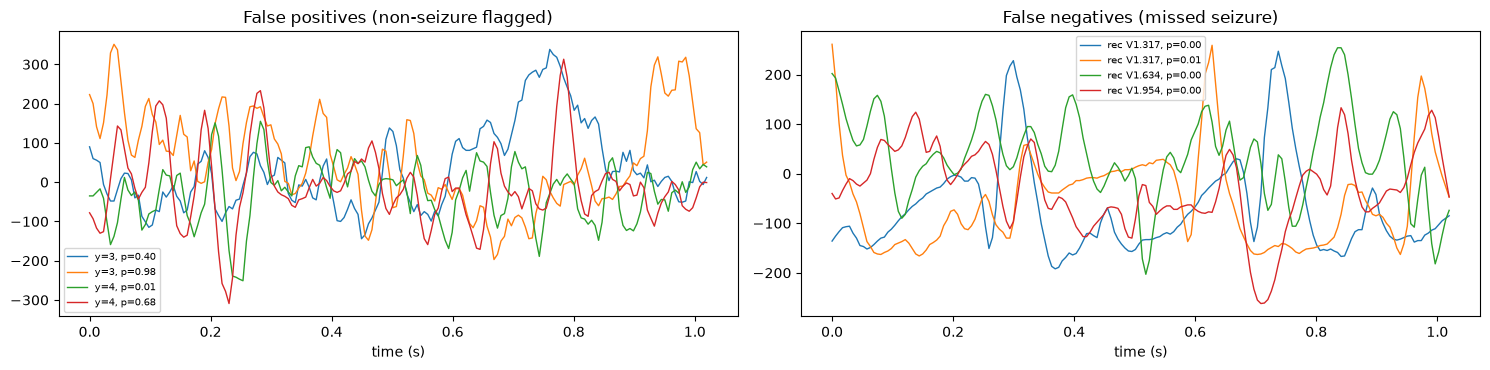

Total test errors: 78 across 14 of 100 recordings
Share of errors in the 10 worst recordings: 94.9%


,label,errors
rec,,
V1.412,3,23
V1.723,2,19
V1.492,3,9
V1.317,1,6
V1.641,4,5
V1.914,2,3
V1.631,4,3
V1.533,2,2
V1.361,4,2


In [13]:
err = pd.DataFrame({"y": yorig_te, "rec": rec_te, "true": yte, "pred": pred_te, "p": p_test})
err["error"] = np.select([(err.true == 0) & (err.pred == 1), (err.true == 1) & (err.pred == 0)], ["FP", "FN"], "correct")
by_label = err.groupby("y").agg(rows=("error", "size"), FP=("error", lambda s: (s == "FP").sum()),
                                FN=("error", lambda s: (s == "FN").sum()))
by_label["FP_rate"] = (by_label.FP / by_label.rows).round(3)
by_label.index = [f"{i}: {label_names[i]}" for i in by_label.index]
display(by_label)

fig, axes = plt.subplots(1, 2, figsize=(15, 3.8))
fp_idx = np.flatnonzero(err.error == "FP")[:4]
fn_idx = np.flatnonzero(err.error == "FN")[:4]
for k in fp_idx:
    axes[0].plot(t, Xte[k], lw=1, label=f"y={yorig_te[k]}, p={p_test[k]:.2f}")
for k in fn_idx:
    axes[1].plot(t, Xte[k], lw=1, label=f"rec {rec_te[k]}, p={p_test[k]:.2f}")
axes[0].set_title("False positives (non-seizure flagged)"); axes[1].set_title("False negatives (missed seizure)")
for ax in axes: ax.set_xlabel("time (s)"); ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

# Do mistakes cluster in particular recordings?
per_rec_err = err.groupby("rec").agg(label=("y", "first"), errors=("error", lambda s: (s != "correct").sum()))
n_err = per_rec_err.errors.sum()
top = per_rec_err.sort_values("errors", ascending=False)
print(f"Total test errors: {n_err} across {(per_rec_err.errors > 0).sum()} of {len(per_rec_err)} recordings")
print(f"Share of errors in the 10 worst recordings: {top.errors.head(10).sum() / max(n_err, 1):.1%}")
display(top.head(10))

In [14]:
rows = []
seg_pos = err.groupby("rec").agg(true=("true", "first"), n_pos=("pred", "sum"))
for k in [1, 2, 3, 5, 8, 12]:
    flag = (seg_pos.n_pos >= k).astype(int)
    tp = ((flag == 1) & (seg_pos.true == 1)).sum(); fn = ((flag == 0) & (seg_pos.true == 1)).sum()
    tn = ((flag == 0) & (seg_pos.true == 0)).sum(); fp = ((flag == 1) & (seg_pos.true == 0)).sum()
    rows.append({"flag if >= k positive segments": k, "recordings": len(seg_pos), "TP": tp, "FN": fn, "FP": fp, "TN": tn,
                 "sensitivity": tp / (tp + fn), "specificity": tn / (tn + fp)})
display(pd.DataFrame(rows).round(3))
print(f"Segment-level (test): sensitivity {test_m['sensitivity']:.3f}, specificity {test_m['specificity']:.3f}")

,flag if >= k positive segments,recordings,TP,FN,FP,TN,sensitivity,specificity
0,1,100,20,0,11,69,1.0,0.862
1,2,100,20,0,9,71,1.0,0.888
2,3,100,20,0,6,74,1.0,0.925
3,5,100,20,0,4,76,1.0,0.950
4,8,100,20,0,3,77,1.0,0.962
5,12,100,20,0,2,78,1.0,0.975


Segment-level (test): sensitivity 0.983, specificity 0.962


### Part E — answers

**Test results (selected model, threshold fixed on validation, test used once):** sensitivity **0.983** (95% CI 0.952–1.000) and specificity **0.962** (95% CI 0.926–0.991). The CIs come from 2,000 bootstrap resamples **of recordings** rather than rows, because rows within a recording are correlated. Compared with validation, sensitivity is a little higher (0.95 → 0.98) and specificity a little lower (0.977 → 0.962). These differences are within the CIs, which are wide because there are only 20 seizure and 80 non-seizure test recordings.

**False positives by original label:** label **3 (healthy brain area in a tumour patient) produced the most false positives (32; 10.7% of its rows)**, followed by label 2 (tumour area, 24; 5.5%) and label 4 (eyes closed, 13). Label 5 (eyes open) produced only 1. Labels 2 and 3 are **intracranial recordings from epilepsy patients** (between seizures). They can contain interictal epileptiform discharges such as spikes and sharp waves, and have larger, sharper waveforms than scalp EEG from healthy volunteers. Those features overlap with the amplitude and line-length features the model relies on. Label 4 (eyes closed) contains strong rhythmic alpha activity, which can resemble rhythmic seizure activity in band-power features. By construction, the 8 false negatives are all seizure segments; 6 of them come from a single seizure recording (`V1.317`).

**Mistakes cluster strongly by recording.** 78 errors occur in only 14 of 100 recordings, and **the 10 worst recordings account for ~95% of errors**. One label-3 recording (`V1.412`) had *all 23* chunks flagged, and one label-2 recording had 19. The model is therefore mostly wrong about *particular recordings* (or people), not randomly wrong about chunks. Those recordings probably have unusual amplitude or rhythm, or interictal activity. This shows that recordings, not rows, are the effective sample size, and that performance on a new person could vary greatly. Before trusting the tool, a clinician would want to inspect such recordings.

**Recording-level aggregation:** flagging a recording if **any** chunk is positive keeps recording sensitivity at 1.00 (20/20) but specificity drops to 0.86 (11 of 80 non-seizure recordings flagged). One false chunk is enough to flag a whole recording. Requiring **k ≥ 5** positive chunks keeps sensitivity 1.00 and raises specificity to 0.95, and k ≥ 12 gives 0.975. Requiring several positive chunks suppresses isolated false alarms, which is how real seizure-detection systems use persistence or duration rules. These numbers rest on only 20 seizure recordings.

## Part F — Reflection

Strong results here do **not** show clinical usefulness. The Bonn data come from just ten people (five healthy volunteers, five epilepsy patients) and carry no person ID, so even my recording-level split may place the same brain in both training and test. Each segment is single-channel and was **hand-selected by experts** to be artefact-free and clearly ictal or non-ictal. The two populations also differ in recording method: healthy volunteers were recorded with scalp electrodes, patients with intracranial electrodes, so a model may partly learn the *recording setup* rather than seizures. The classes are artificially balanced (20% seizure versus well under 1% in real monitoring), so PPV collapses at realistic prevalence. There is no clinical context such as medication, sleep state or other channels.

Before anyone considered hospital use, the tool would need **external validation** on continuous, multi-channel, unselected EEG (e.g. long-term scalp EEG from other centres such as the CHB-MIT or TUH corpora). That validation should use patient-level splits, include artefacts (chewing, movement, electrode pops), cover different ages, devices and seizure types, and report sensitivity, false alarms per hour and detection latency. Ideally it would end with a prospective study comparing clinician review with and without the tool.

In the workflow, the tool should only **prioritise** segments for a qualified neurophysiologist, who makes every decision. To avoid alert fatigue: use persistence rules (k positive segments), cap alerts per hour, show the probability and the flagged trace instead of a bare alarm, and monitor override and false-alarm rates after deployment.